In [ ]:
4.7: High-Pass Filtering

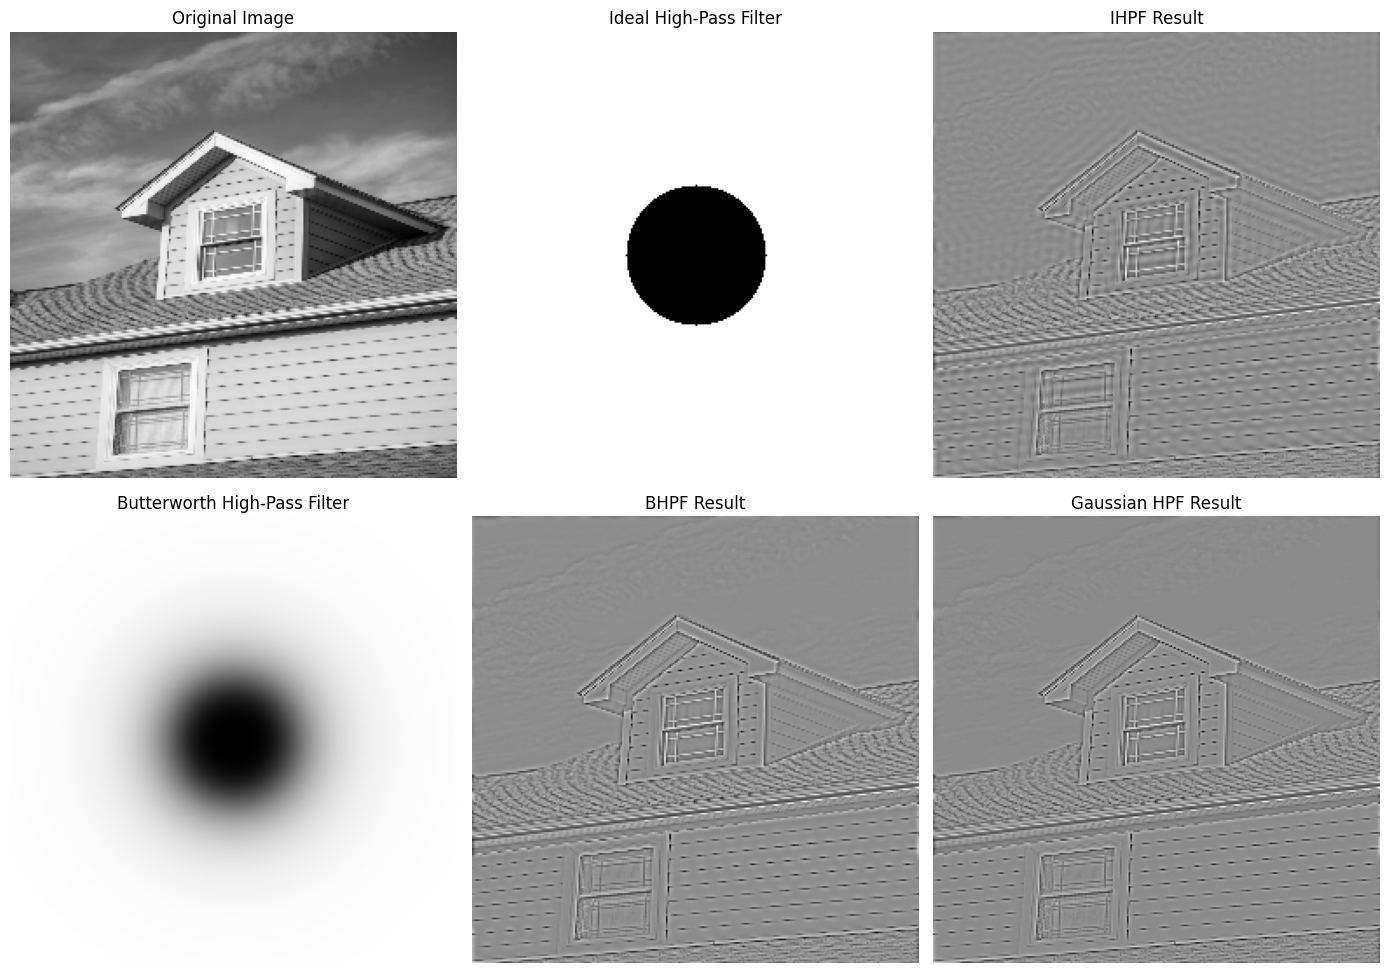

Assignment 4.7 Completed Successfully!
All output images saved in Colab.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# Step 1: Load Original Image
image_files = (
    glob.glob('/content/*.png') +
    glob.glob('/content/*.jpg') +
    glob.glob('/content/*.jpeg')
)

if not image_files:
    raise FileNotFoundError("Please upload an image to Colab.")

image_path = next(
    (f for f in image_files if os.path.basename(f) == "image.png"),
    image_files[0]
)

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

img = cv2.resize(img, (256, 256))

# Step 2: Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

# Step 3: Create Distance Matrix
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V = np.meshgrid(v, u)

D = np.sqrt(U**2 + V**2)

# Cutoff Frequency and Order
D0 = 40
n = 2

# Step 4: Ideal High-Pass Filter
IHPF = np.ones((rows, cols), dtype=np.float32)
IHPF[D <= D0] = 0

# Step 5: Butterworth High-Pass Filter
BHPF = 1 / (1 + (D0 / (D + 1e-10))**(2 * n))

# Step 6: Gaussian High-Pass Filter
GHPF = 1 - np.exp(-(D**2) / (2 * D0**2))

# Step 7: Apply Filters
G_ideal = F_shift * IHPF
G_butterworth = F_shift * BHPF
G_gaussian = F_shift * GHPF

# Step 8: Inverse Fourier Transform
def inverse_fft(G):
    result = np.fft.ifft2(np.fft.ifftshift(G))
    return np.real(result)

result_ideal = inverse_fft(G_ideal)
result_butterworth = inverse_fft(G_butterworth)
result_gaussian = inverse_fft(G_gaussian)

# Step 9: Normalize Results for Display
def normalize_image(image):
    return cv2.normalize(
        image, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

ideal_display = normalize_image(result_ideal)
butterworth_display = normalize_image(result_butterworth)
gaussian_display = normalize_image(result_gaussian)

# Step 10: Display Results
plt.figure(figsize=(14, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(IHPF, cmap='gray')
plt.title("Ideal High-Pass Filter")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(ideal_display, cmap='gray')
plt.title("IHPF Result")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(BHPF, cmap='gray')
plt.title("Butterworth High-Pass Filter")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(butterworth_display, cmap='gray')
plt.title("BHPF Result")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(gaussian_display, cmap='gray')
plt.title("Gaussian HPF Result")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 11: Save Output Images
cv2.imwrite(
    "/content/Assignment_4_7_IHPF.png",
    ideal_display
)

cv2.imwrite(
    "/content/Assignment_4_7_BHPF.png",
    butterworth_display
)

cv2.imwrite(
    "/content/Assignment_4_7_GHPF.png",
    gaussian_display
)

print("Assignment 4.7 Completed Successfully!")
print("All output images saved in Colab.")